In [1]:
# ============================================================
# Cell 1
# Imports
# ============================================================

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from src.kitti_raw_dataset import KITTIRawDataset

plt.rcParams["figure.figsize"]=(10,6)


In [2]:
# ============================================================
# Cell 2
# Initialize KITTI Raw Dataset
# ============================================================

DRIVE = "2011_09_26_drive_0001_sync"

DATASET = KITTIRawDataset(
    dataset_root=r"D:\Research\Datasets\KITTI",
    drive=DRIVE
)

DATASET.validate()


Drive                    : FOUND
Images                   : FOUND
OXTS                     : FOUND
Camera Calibration       : FOUND
IMU Calibration          : FOUND
Velodyne Calibration     : FOUND


In [3]:
# ============================================================
# Cell 3
# Dataset Summary
# ============================================================

summary = DATASET.summary()
display(summary)

print("Frame Count :", DATASET.get_frame_count())


,Property,Value
0,Drive,2011_09_26_drive_0001_sync
1,Total Frames,108
2,Image Width,1242
3,Image Height,375


Frame Count : 108


(375, 1242, 3)


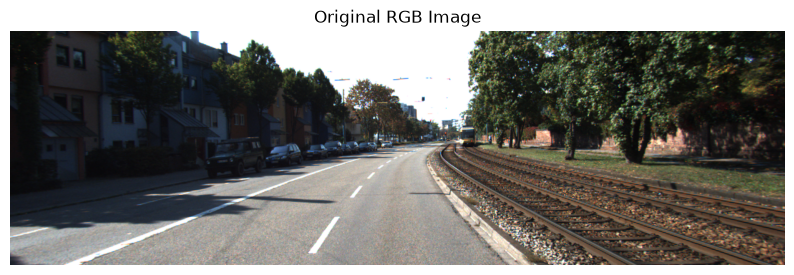

In [4]:
# ============================================================
# Cell 4
# Load Sample
# ============================================================

sample = DATASET.load_sample(frame=0)

raw_image = sample["image"]

print(raw_image.shape)

plt.imshow(raw_image)
plt.title("Original RGB Image")
plt.axis("off")
plt.show()


In [5]:
# ============================================================
# Cell 5
# OXTS Sample
# ============================================================

print("Number of Values :", len(sample["oxts"]))
print()
print(sample["oxts"])


Number of Values : 30

[ 4.90150038e+01  8.43429710e+00  1.16430328e+02  3.57520000e-02
  9.03000000e-03 -2.60870698e+00 -6.81144148e+00 -1.12756418e+01
  1.31727167e+01 -1.24752643e-01 -3.29199030e-02 -4.45198146e-01
  4.29573698e-02  1.02098653e+01 -3.40300922e-01 -3.16869154e-01
  1.02091178e+01  9.09517557e-03 -2.31407413e-02 -1.79090345e-02
  8.90180022e-03 -2.24952994e-02 -1.88093309e-02  2.76586334e-02
  1.27279221e-02  4.00000000e+00  1.10000000e+01  6.00000000e+00
  6.00000000e+00  6.00000000e+00]


In [6]:
# ============================================================
# Cell 6
# Calibration
# ============================================================

calibration = DATASET.load_calibration()
print(calibration.keys())


dict_keys(['calib_cam_to_cam', 'calib_imu_to_velo', 'calib_velo_to_cam'])


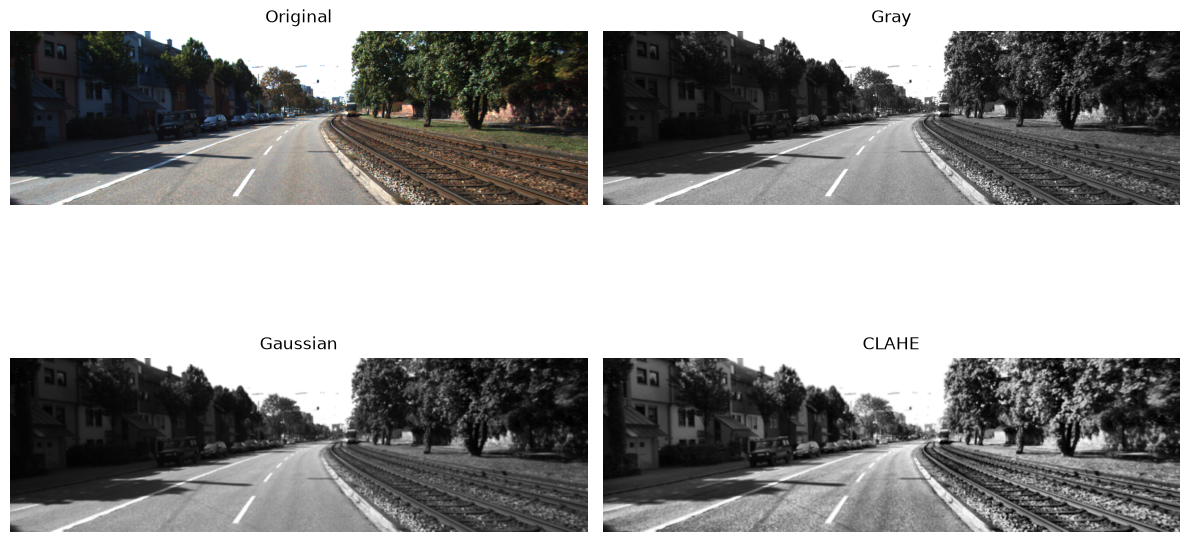

In [7]:
# ============================================================
# Cell 7
# Image Preprocessing
# ============================================================

gray = cv2.cvtColor(raw_image, cv2.COLOR_RGB2GRAY)

normalized = cv2.normalize(
    gray, None, 0, 255, cv2.NORM_MINMAX
)

blurred = cv2.GaussianBlur(
    normalized, (5,5), 0
)

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8,8)
)

enhanced = clahe.apply(blurred)

fig, ax = plt.subplots(2,2, figsize=(12,8))

ax[0,0].imshow(raw_image)
ax[0,0].set_title("Original")
ax[0,0].axis("off")

ax[0,1].imshow(gray, cmap="gray")
ax[0,1].set_title("Gray")
ax[0,1].axis("off")

ax[1,0].imshow(blurred, cmap="gray")
ax[1,0].set_title("Gaussian")
ax[1,0].axis("off")

ax[1,1].imshow(enhanced, cmap="gray")
ax[1,1].set_title("CLAHE")
ax[1,1].axis("off")

plt.tight_layout()
plt.show()


In [8]:
# ============================================================
# Cell 8
# Processed Frame
# ============================================================

processed_frame = {

    "frame": sample["frame"],

    "raw_image": raw_image,

    "gray_image": gray,

    "normalized_image": normalized,

    "blurred_image": blurred,

    "enhanced_image": enhanced,

    "oxts": sample["oxts"],

    "calibration": sample["calibration"]

}

print("="*70)
print("NOTEBOOK 03 COMPLETED SUCCESSFULLY")
print("="*70)
print("Drive :", DRIVE)
print("Frame :", processed_frame["frame"])
print("Processed Image Shape :", processed_frame["enhanced_image"].shape)


NOTEBOOK 03 COMPLETED SUCCESSFULLY
Drive : 2011_09_26_drive_0001_sync
Frame : 0
Processed Image Shape : (375, 1242)
